# Stage 5 — So sánh classifier DTDLINK

## Tóm tắt
Ba model cùng học trên 384.832 URL train và được chấm trên 129.332 URL validation; test được giữ kín. Ở ngưỡng 0,5, Random Forest đạt precision 84,52%, recall 93,58% và F1 88,82%; Decision Tree đạt 79,82%, 93,93%, 86,30%; Logistic Regression đạt 77,17%, 79,30%, 78,22%. Random Forest bỏ sót 2.758 URL nguy hiểm và cảnh báo nhầm 7.357 URL. Nhóm đã chọn Random Forest với ngưỡng 0,5. Đây vẫn là kết quả validation, chưa phải kết quả cuối trên test.

**Cách tạo lại đầu vào notebook:** chạy `PYTHONPATH=src .venv/bin/python src/dtdlink_ml/train_classifier.py` từ thư mục gốc dự án; sau đó chạy notebook từ đầu. Lệnh huấn luyện kiểm tra SHA-256 của bảng đặc trưng và split manifest trước khi tạo báo cáo.

## Bối cảnh và phương pháp
DTDLINK phân loại `benign` (0) và `potentially_dangerous` (1) bằng 36 đặc trưng lấy từ chuỗi URL. Logistic Regression chuẩn hóa đặc trưng bằng thống kê train; Decision Tree và Random Forest dùng đặc trưng gốc. Random Forest gộp 100 cây với seed 42; tất cả model xử lý lệch lớp bằng class weight.

### Giả định quan trọng
- Mỗi registrable domain chỉ nằm trong một split; manifest Stage 4 là cố định.
- Ngưỡng 0,5 là mốc đầu tiên, chưa phải quyết định cuối.
- Validation vừa dùng để so sánh vừa xem các ngưỡng, nên kết quả sau lựa chọn có thể lạc quan; test chỉ mở ở Stage 7.
- Cách ghi scheme có liên hệ với nguồn dữ liệu; kết quả có thể chịu ảnh hưởng của dấu hiệu nguồn.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / "reports" / "classification").exists():
    root = root.parent
report = root / "reports" / "classification"
summary = json.loads((report / "validation_summary.json").read_text(encoding="utf-8"))
train = pd.read_csv(report / "train_metrics.csv")
validation = pd.read_csv(report / "validation_metrics.csv")
thresholds = pd.read_csv(report / "threshold_tradeoffs.csv")
subgroups = pd.read_csv(report / "validation_subgroups.csv")
assert summary["test_used_for_modelling_or_metrics"] is False
assert summary["split_counts"] == {"train": 384832, "validation": 129332, "test": 126949}
print("Nguồn:", report)
print("Số đặc trưng:", len(summary["feature_names"]))

Nguồn: /Users/okok/Documents/innovationproject cos30049/reports/classification
Số đặc trưng: 36


## Kết quả ở ngưỡng 0,5
**Recall**: trong các URL nguy hiểm thật, model bắt được bao nhiêu. **Precision**: trong các URL model cảnh báo, bao nhiêu là nguy hiểm thật. `false_negative` là URL nguy hiểm bị bỏ sót.

In [2]:
columns = ["model", "accuracy", "precision", "recall", "f1", "false_positive", "false_negative"]
comparison = validation[columns].merge(train[["model", "f1"]].rename(columns={"f1": "train_f1"}), on="model")
comparison["f1_gap_train_minus_validation"] = comparison["train_f1"] - comparison["f1"]
display(comparison.round(4))

model,accuracy,precision,recall,f1,false_positive,false_negative,train_f1,f1_gap_train_minus_validation
logistic_regression,0.8534,0.7717,0.7930,0.7822,10074,8885,0.8072,0.0250
decision_tree,0.9010,0.7982,0.9393,0.8630,10195,2604,0.9283,0.0653
random_forest,0.9218,0.8452,0.9358,0.8882,7357,2758,0.9235,0.0353


## Ngưỡng thay đổi sự đánh đổi ra sao?
Ngưỡng thấp hơn thường bắt được thêm URL nguy hiểm và đồng thời làm tăng cảnh báo nhầm. Đường bên dưới chỉ dùng validation, không dùng test.

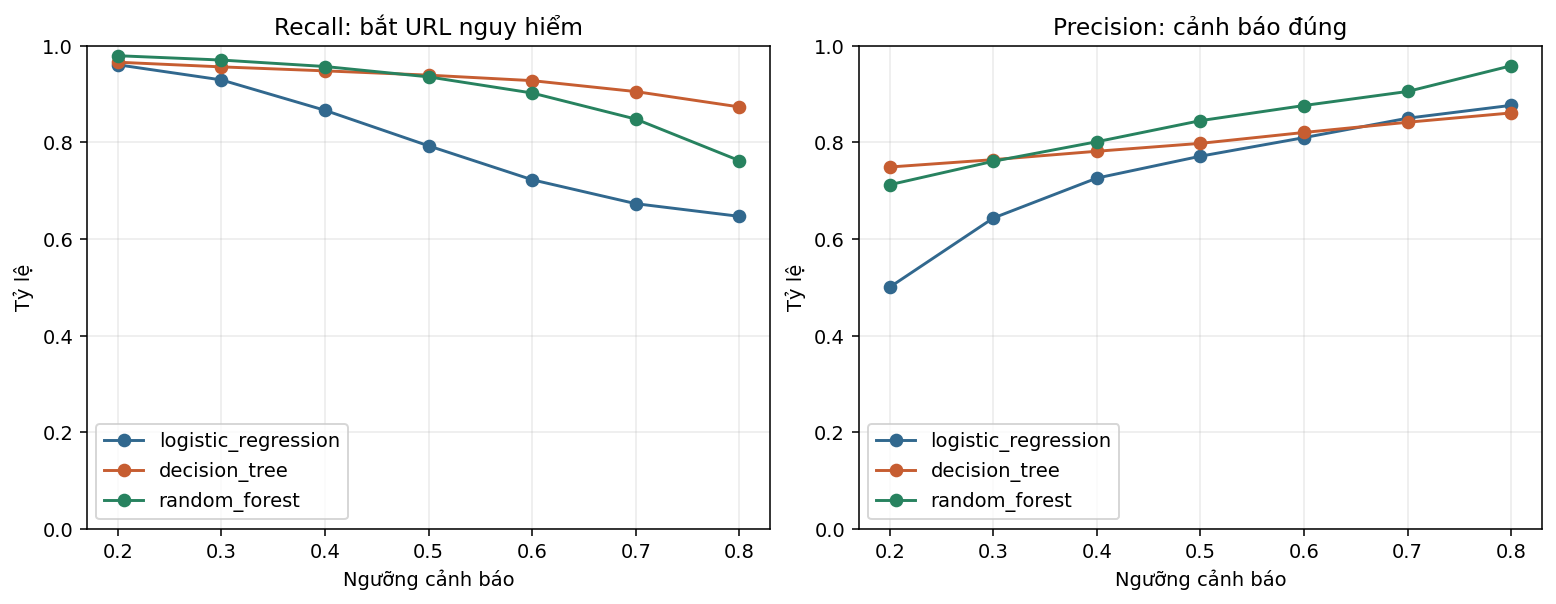

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
colors = {"logistic_regression": "#31688e", "decision_tree": "#c65d31", "random_forest": "#27825f"}
for name, group in thresholds.groupby("model", sort=False):
    axes[0].plot(group["threshold"], group["recall"], marker="o", label=name, color=colors[name])
    axes[1].plot(group["threshold"], group["precision"], marker="o", label=name, color=colors[name])
for ax, title in zip(axes, ["Recall: bắt URL nguy hiểm", "Precision: cảnh báo đúng"]):
    ax.set_title(title)
    ax.set_xlabel("Ngưỡng cảnh báo")
    ax.set_ylabel("Tỷ lệ")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## Nhóm nhãn gốc và giới hạn
Bảng này giúp xem model bỏ sót ở phishing, malware hay defacement. Các nhãn gốc chỉ dùng để phân tích validation; model vẫn dự đoán hai lớp.

In [4]:
display(subgroups)
print("Đã chọn:", summary["selected_model"], "ngưỡng", summary["selected_threshold"])
print("Tập test còn khóa; đánh giá cuối thuộc Stage 7.")

Đã chọn: random_forest ngưỡng 0.5
Tập test còn khóa; đánh giá cuối thuộc Stage 7.


model,source_type,rows,correct,missed_dangerous,false_alarms
logistic_regression,benign,86400,76326,0,10074
logistic_regression,phishing,18993,10841,8152,0
logistic_regression,malware,4814,4554,260,0
logistic_regression,defacement,19125,18652,473,0
decision_tree,benign,86400,76205,0,10195
decision_tree,phishing,18993,16879,2114,0
decision_tree,malware,4814,4614,200,0
decision_tree,defacement,19125,18835,290,0
random_forest,benign,86400,79043,0,7357
random_forest,phishing,18993,16667,2326,0


## Quyết định và bước tiếp theo
Nhóm đã chọn Random Forest với ngưỡng **0,5**. Trên validation, nó có precision 84,52%, recall 93,58%, F1 88,82%, bỏ sót 2.758 URL nguy hiểm và cảnh báo nhầm 7.357 URL. So với Decision Tree cùng ngưỡng, nó giảm 2.838 cảnh báo nhầm nhưng bỏ sót thêm 154 URL nguy hiểm. Đây là sự đánh đổi đã được nhóm chấp nhận.

Khoảng cách F1 train–validation của Random Forest khoảng 0,035. URL scheme có thể phản ánh nguồn thu thập; kết quả validation còn chịu ảnh hưởng của việc chọn model và ngưỡng trên chính tập này. Tập test được giữ cho Stage 7. Xác suất từ model chưa được hiệu chuẩn thành điểm tin cậy của sản phẩm.